# Netflix Data Analysis

**Project Domain:** Entertainment Analytics | Data Analysis | Business Intelligence

**Project Objective:**

The objective of this project is to analyze Netflix movies and TV shows data to understand content distribution, identify popular content ratings, explore country-wise contributions, and examine release-year trends. The project focuses on cleaning real-world data containing missing values and presenting visual insights that support data-driven understanding of Netflix's content library.

**Skills:**

- Python
- Pandas
- NumPy
- Data Cleaning & Preprocessing
- Missing Value Treatment
- Exploratory Data Analysis (EDA)
- Data Visualization (Matplotlib & Seaborn)
- Correlation Analysis
- Business Insight Generation

**Dataset Description**

**Dataset Name:**
- Netflix Movies and TV Shows Dataset

**Dataset Details:**
- Records: 8,807
- Features: 12
- Data Source: Kaggle — Netflix Movies and TV Shows Dataset

**Key Attributes:**

- Content information: `show_id`, `title`, `type`
- People involved: `director`, `cast`
- Geographic information: `country`
- Release details: `date_added`, `release_year`
- Content classification: `rating`, `listed_in`
- Additional information: `duration`, `description`

**Project Outcome:**

The project provides insights into the distribution of Movies and TV Shows, content ratings, country-wise content contributions, and release-year patterns using Python-based data analysis and visualization techniques.


In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib as plt

**Step 1:- Data Loading & Understanding**

In [3]:
df=pd.read_csv("/content/netflix_titles.csv")
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [5]:
df.shape

(8807, 12)

In [6]:
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='object')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [39]:
df.describe()

,release_year
count,8807.000000
mean,2014.180198
std,8.819312
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


Objective :-

* Understand Data & its type.
* Identify numerical & categorical columns.
* Dectect missing values.
* understand stat's representation.

Step 2: Data Cleaning Process

* Removing Irrelevant columns.

* Missing Data Detection

In [12]:
df.isnull().sum()

,0
show_id,0
type,0
title,0
director,2634
cast,825
country,831
date_added,10
release_year,0
rating,4
duration,3


Observed Missing Columns:-

* director
* cast
* country
* date_added
* rating
* duration



In [13]:
df.isnull().sum().sum()

np.int64(4307)

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
(df.isnull().sum() / len(df) * 100).round(2)

,0
show_id,0.00
type,0.00
title,0.00
director,29.91
cast,9.37
country,9.44
date_added,0.11
release_year,0.00
rating,0.05
duration,0.03


In [16]:
cols = ['director', 'cast', 'country',
        'date_added', 'rating', 'duration']

df[cols] = df[cols].fillna('Unknown')

In [17]:
df.isnull().sum()

,0
show_id,0
type,0
title,0
director,0
cast,0
country,0
date_added,0
release_year,0
rating,0
duration,0


In [18]:
df[['director', 'cast', 'country']].head(10)

,director,cast,country
0,Kirsten Johnson,Unknown,United States
1,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa
2,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown
3,Unknown,Unknown,Unknown
4,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India
5,Mike Flanagan,"Kate Siegel, Zach Gilford, Hamish Linklater, H...",Unknown
6,"Robert Cullen, José Luis Ucha","Vanessa Hudgens, Kimiko Glenn, James Marsden, ...",Unknown
7,Haile Gerima,"Kofi Ghanaba, Oyafunmike Ogunlano, Alexandra D...","United States, Ghana, Burkina Faso, United Kin..."
8,Andy Devonshire,"Mel Giedroyc, Sue Perkins, Mary Berry, Paul Ho...",United Kingdom
9,Theodore Melfi,"Melissa McCarthy, Chris O'Dowd, Kevin Kline, T...",United States


In [19]:
df.duplicated().sum()

np.int64(0)

In [20]:
df.shape

(8807, 12)

In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      8807 non-null   object
 4   cast          8807 non-null   object
 5   country       8807 non-null   object
 6   date_added    8807 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8807 non-null   object
 9   duration      8807 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [23]:
df['type'].value_counts()

,count
type,
Movie,6131
TV Show,2676


In [24]:
df['type'].value_counts(normalize=True).mul(100).round(2)

,proportion
type,
Movie,69.62
TV Show,30.38


**Step 3: Exploratory Data Analysis (EDA)**

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

Q1. What is the distribution of Netflix content types?

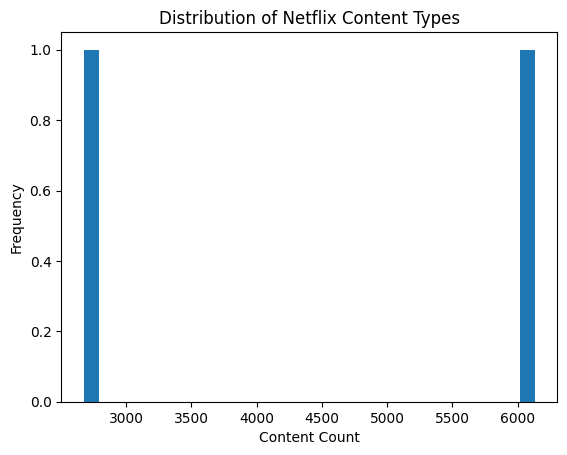

In [29]:
plt.figure()
plt.hist(
    df['type'].value_counts(),bins=30)
plt.title("Distribution of Netflix Content Types")
plt.xlabel("Content Count")
plt.ylabel("Frequency")
plt.show()


Analysis:
- Movies account for the majority of Netflix titles.
- TV Shows make up a smaller proportion of the total content.

Conclusion:

- Netflix's content library is dominated by Movies, while TV Shows represent a smaller share of the available titles.

Q2. Which are the most common ratings on Netflix?

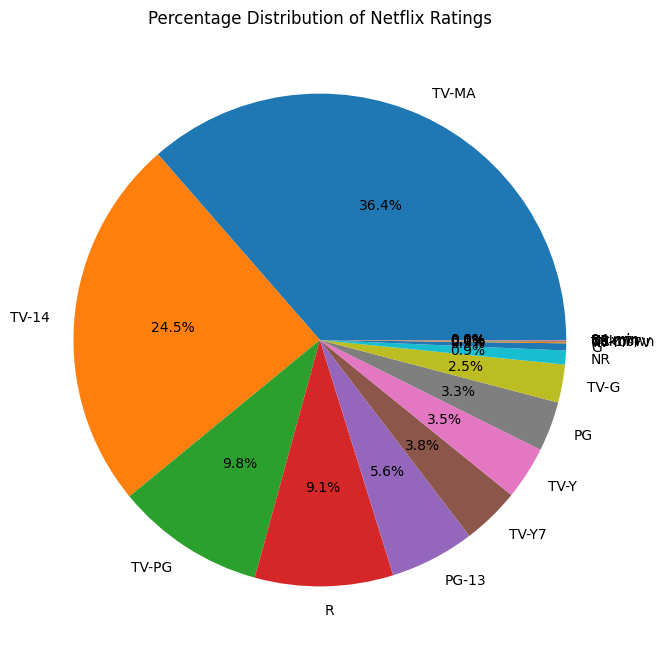

In [31]:
plt.figure(figsize=(8, 8))

df['rating'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%'
)

plt.title("Percentage Distribution of Netflix Ratings")
plt.ylabel("")
plt.show()

Q3. Is there a relationship between release year and Netflix content?

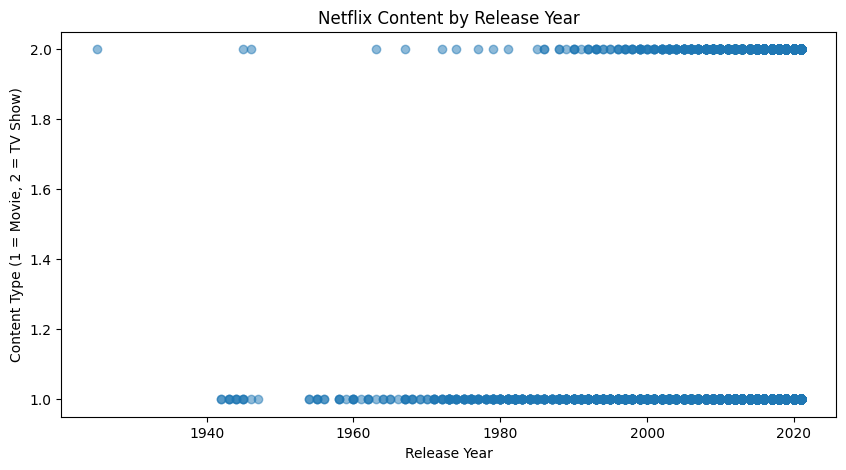

In [32]:
plt.figure(figsize=(10, 5))

plt.scatter(df['release_year'], df['type'].map({
    'Movie': 1,
    'TV Show': 2
}), alpha=0.5)

plt.xlabel("Release Year")
plt.ylabel("Content Type (1 = Movie, 2 = TV Show)")
plt.title("Netflix Content by Release Year")
plt.show()

Analysis:-
- Netflix titles are distributed across many release years.
- The scatter plot shows the release years of Movies and TV Shows.
- The density of points in recent years helps identify periods with more titles in the dataset.

Conclusion:-
- Netflix's library includes content released over several decades, with the plot helping compare the release-year distribution of Movies and TV Shows.

Q4. Relationship Between Content Type and Release Year

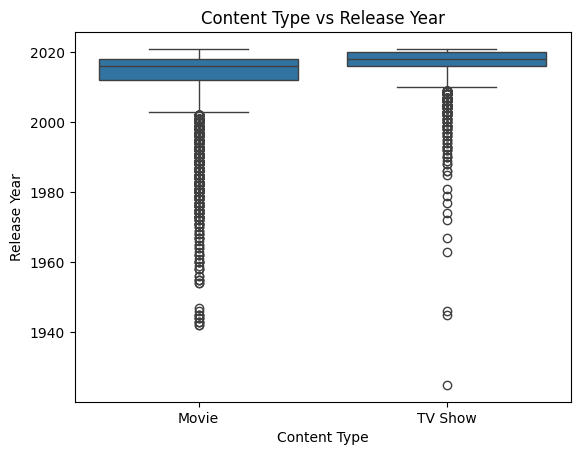

In [34]:
sns.boxplot(x='type', y='release_year', data=df)

plt.xlabel("Content Type")
plt.ylabel("Release Year")
plt.title("Content Type vs Release Year")
plt.show()

Analysis:-
- The boxplot compares the release years of Movies and TV Shows.
- The median line shows the middle release year for each content type.
- The boxes show the middle 50% of release years.
- Points outside the whiskers indicate potential outliers, such as older release years.

Conclusion:-

- The boxplot helps compare the release-year distributions of Movies and TV Shows on Netflix and identify differences in their median release years and spread.

Q5. Which countries have the most titles on Netflix?

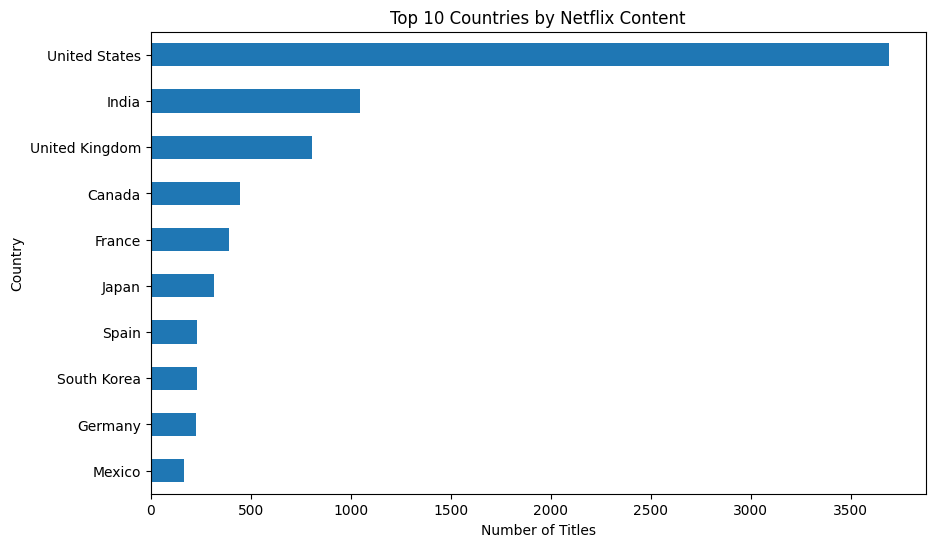

In [35]:
country_counts = df[df['country'] != 'Unknown']['country'].str.split(', ').explode()

top_countries = country_counts.value_counts().head(10)

plt.figure(figsize=(10, 6))
top_countries.sort_values().plot(kind='barh')

plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.title("Top 10 Countries by Netflix Content")
plt.show()

Analysis:-
- The graph displays the top 10 countries with the highest number of Netflix titles.
- Countries with longer bars contribute more titles to the dataset.
- Some titles are associated with multiple countries, so a title may be counted for more than one country.

Conclusion:-

- The graph helps identify the countries that contribute the most content to Netflix and compare their representation in the platform's library.

Q6. How has Netflix content grown over the years?

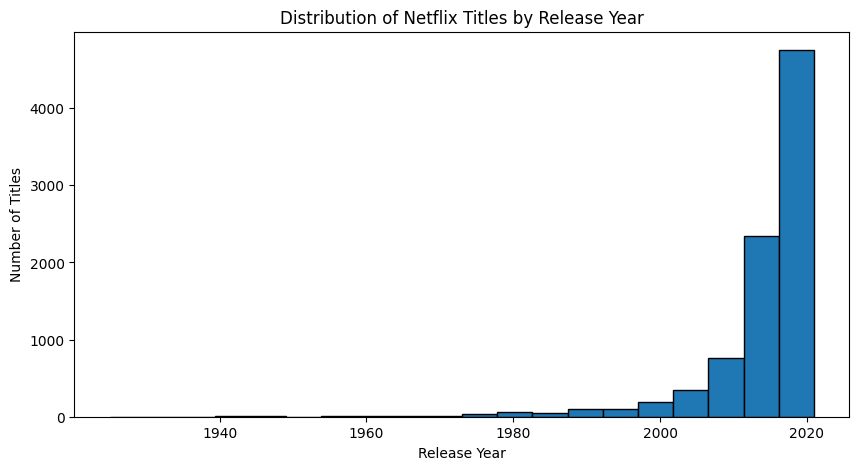

In [36]:
plt.figure(figsize=(10, 5))

plt.hist(df['release_year'], bins=20, edgecolor='black')

plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.title("Distribution of Netflix Titles by Release Year")
plt.show()

Analysis:-
- The histogram shows the distribution of Netflix titles across different release years.
- Each bar represents the number of titles within a range of years.
- Taller bars indicate periods with more titles in the dataset.

Conclusion:-

- The histogram helps us understand how Netflix titles are distributed across release-year ranges and identify periods with more content.

Q7. Correlation Heatmap of Netflix Content

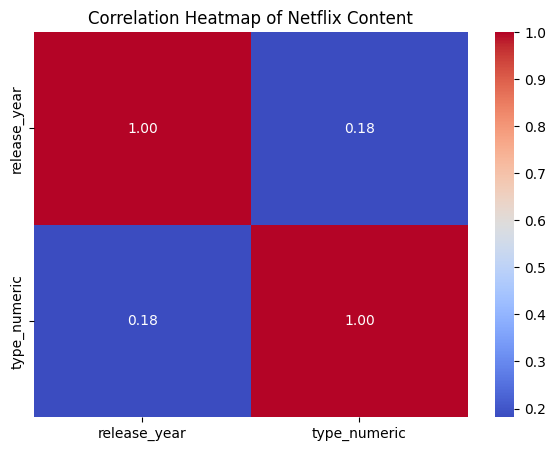

In [37]:
df_corr = df.copy()

df_corr['type_numeric'] = df_corr['type'].map({
    'Movie': 0,
    'TV Show': 1
})

corr = df_corr[['release_year', 'type_numeric']].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')

plt.title("Correlation Heatmap of Netflix Content")
plt.show()

Analysis:-
- The heatmap displays the correlation between release year and content type.
- Correlation values range from -1 to +1.
- Values closer to +1 indicate a positive linear relationship, while values closer to -1 indicate a negative linear relationship.
- Since Movie and TV Show are categorical types converted into numbers, interpret this correlation cautiously.

Conclusion:-

- The heatmap provides a basic view of the relationship between release year and content type. However, correlation does not imply causation, and this limited heatmap does not show relationships among other Netflix features.

Step 4:

Data Visualization Dashboard
The Netflix Data Analysis dashboard presents important insights into the content available on Netflix using different data visualization techniques, including bar charts, pie charts, boxplots, histograms, and heatmaps.

Key Business Insights (Analytics Outcome)
- Movies dominate the Netflix library: Movies represent a larger share of Netflix titles than TV Shows.
- Content ratings reveal audience categories: Ratings such as TV-MA and TV-14 help understand the age categories targeted by Netflix content.
- Countries contribute to global content diversity: Country-wise analysis identifies the countries contributing the most titles to the dataset.
- Release years reveal content distribution: Histograms and boxplots help identify the distribution, median, spread, and older release years of Netflix titles.
- Data cleaning improves analysis: Treating missing values and checking duplicate records makes the dataset more consistent for visualization.

Final Conclusion:

This project successfully transformed the raw Netflix dataset into a clean, structured, and insight-driven dataset through data cleaning, missing value treatment, duplicate checking, and exploratory data analysis.

By applying Python libraries such as Pandas, NumPy, Matplotlib, and Seaborn, meaningful insights were extracted about content types, ratings, country-wise distribution, and release years. These findings help understand Netflix's content library and provide a foundation for data-driven decisions about content distribution and audience preferences.

Overall, this project strengthened practical skills in data cleaning, exploratory data analysis, and data visualization, which are essential for Data Analyst roles.